# The University of Azad Jammu and Kashmir
**Department of Software Engineering — Digital Image Processing Lab**
Lab Instructor: Engr. Fahad Nisar | Semester: Fifth | Session: 2024-28 (SE)

## Lab Task # 03 — Image Enhancement and Intensity Transformations

| | |
|---|---|
| **Name** | *Muneeba Arshad* |
| **Roll No** | *2024-SE-06* |
| **Assigned / Due** | November 02, 2026 / November 09, 2026, 11:59 PM |

**Objective:** Calculate, implement and compare grayscale intensity transformations, histogram enhancement and thresholding while preventing overflow and interpreting their effects.

**Input image:** `input_image.png` (8-bit grayscale, ≥ 300 × 300). *Replace this file with your own personally selected JPG/PNG and re-run all cells from a restarted kernel.*

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})

# ---------- helper functions used throughout the notebook ----------
def to_u8(x):
    """Clip to 0-255 FIRST, then convert to uint8 (float values are truncated, not rounded)."""
    return np.clip(x, 0, 255).astype(np.uint8)

def show(images, titles, ncols=None, size=4, suptitle=None):
    """Display grayscale images with the fixed display range 0-255."""
    n = len(images); ncols = ncols or n; nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t); ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

def hist256(image):
    return cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()

def plot_hist(ax, image, title):
    ax.bar(np.arange(256), hist256(image), width=1.0, color="gray")
    ax.set_xlim(0, 256)
    ax.set_xlabel("Intensity level (0-255)"); ax.set_ylabel("Pixel count"); ax.set_title(title)

def table(headers, rows, title=None):
    """Print a small aligned text table (used for dry-run verification)."""
    if title: print(title)
    cols = list(zip(*([[str(h) for h in headers]] + [[str(c) for c in r] for r in rows])))
    w = [max(len(x) for x in col) for col in cols]
    print(" | ".join(str(h).ljust(k) for h, k in zip(headers, w)))
    print("-+-".join("-" * k for k in w))
    for r in rows:
        print(" | ".join(str(c).ljust(k) for c, k in zip(r, w)))
    print()

def stats(x):
    return f"mean={x.mean():6.1f}  std={x.std():6.1f}  min={x.min():3d}  max={x.max():3d}"

def quadrant(x):
    h, w = x.shape
    return [x[:h//2, :w//2], x[:h//2, w//2:], x[h//2:, :w//2], x[h//2:, w//2:]]

def flattest_block(x, size=16):
    """Top-left corner of the smoothest 16x16 block (blocks with std < 0.5 are ignored as saturated/constant)."""
    h, w = (x.shape[0] // size) * size, (x.shape[1] // size) * size
    b = x[:h, :w].astype(np.float64).reshape(h // size, size, w // size, size).swapaxes(1, 2)
    s = b.std(axis=(2, 3)); s[s < 0.5] = np.inf
    i, j = np.unravel_index(np.argmin(s), s.shape)
    return i * size, j * size

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.4.6


##  Load and validate the grayscale image
The image is read as 8-bit grayscale and **kept unchanged** (made read-only). Every transformation creates a *new* array.

Shape : (400, 600)
dtype : uint8
Min   : 0
Max   : 255


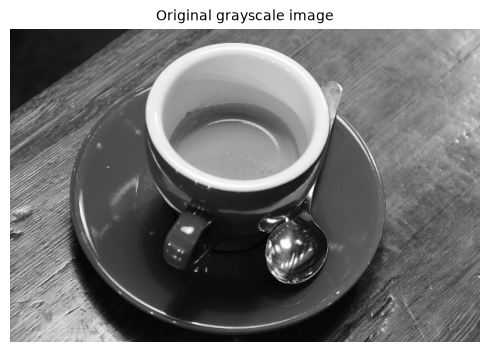

In [2]:
IMAGE_PATH = "input_image.png"          # <- put your own JPG/PNG here

img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Could not read '{IMAGE_PATH}'. Place the image next to the notebook.")

# ---- validation ----
assert img.ndim == 2,            "image must be single-channel grayscale"
assert img.dtype == np.uint8,    "image must be 8-bit (uint8)"
assert min(img.shape) >= 300,    "image must be at least 300 x 300 pixels"

original = img.copy()
img.setflags(write=False)               # protect the original from accidental modification

print("Shape :", img.shape)
print("dtype :", img.dtype)
print("Min   :", img.min())
print("Max   :", img.max())
show([img], ["Original grayscale image"], size=5)

## 1. Brightness adjustment  ( s = r + β )
Wider arithmetic type (`int16`) is used so values such as 240 + 40 = 280 do **not** wrap around in `uint8`; the result is clipped to 0–255 and only then converted to `uint8`.

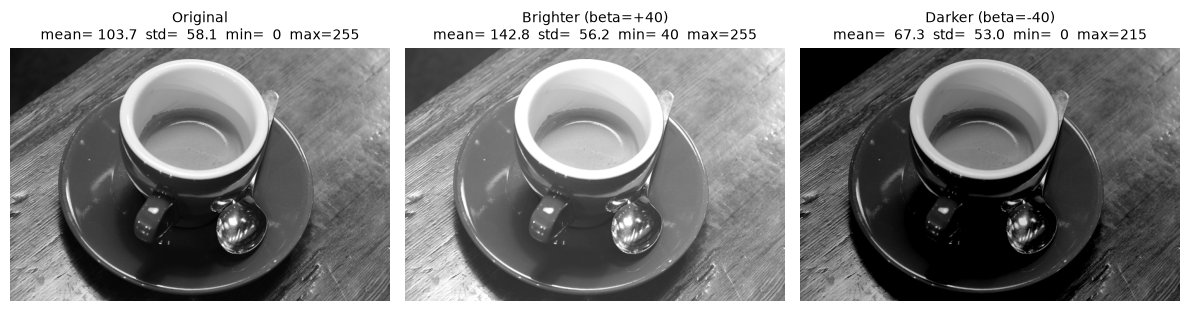

Pixels that wrapped around with naive uint8 addition: 10466


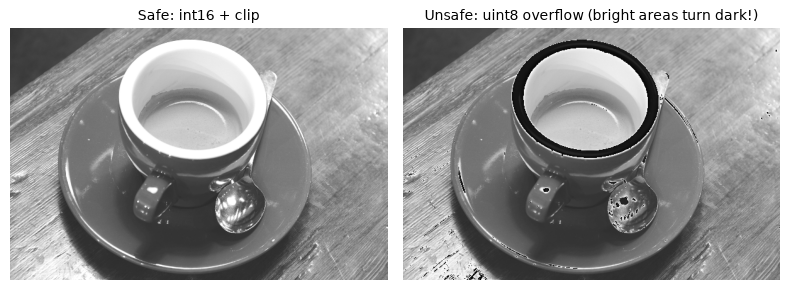

In [3]:
bright = to_u8(img.astype(np.int16) + 40)     # beta = +40
dark   = to_u8(img.astype(np.int16) - 40)     # beta = -40

show([img, bright, dark],
     [f"Original\n{stats(img)}", f"Brighter (beta=+40)\n{stats(bright)}", f"Darker (beta=-40)\n{stats(dark)}"])

# --- Why overflow matters: the same +40 done naively in uint8 wraps around (e.g. 250 + 40 -> 34) ---
wrapped = img + 40                            # uint8 arithmetic -> modulo-256 wrap-around (WRONG)
print("Pixels that wrapped around with naive uint8 addition:", int((img.astype(int) + 40 > 255).sum()))
show([bright, wrapped], ["Safe: int16 + clip", "Unsafe: uint8 overflow (bright areas turn dark!)"])

In [4]:
# --- +40 implemented with nested loops, compared with the NumPy result ---
h, w = img.shape
loop_bright = np.zeros_like(img)
for i in range(h):
    for j in range(w):
        v = int(img[i, j]) + 40               # Python int: no uint8 overflow
        if v > 255: v = 255
        elif v < 0: v = 0
        loop_bright[i, j] = v

print("Nested-loop result identical to NumPy result:", np.array_equal(loop_bright, bright))
assert np.array_equal(loop_bright, bright)

Nested-loop result identical to NumPy result: True


### Dry run 1 — Brightness (pixels = [30, 80, 128, 180, 240])

| r | r + 40 (raw) | clipped | uint8 | r − 40 (raw) | clipped | uint8 |
|---|---|---|---|---|---|---|
| 30  | 70  | 70  | 70  | −10 | **0** | 0 |
| 80  | 120 | 120 | 120 | 40  | 40  | 40 |
| 128 | 168 | 168 | 168 | 88  | 88  | 88 |
| 180 | 220 | 220 | 220 | 140 | 140 | 140 |
| 240 | 280 | **255** | 255 | 200 | 200 | 200 |

**Lost detail:** with +40, 240 → 280 is clipped to 255, and *every* original value ≥ 215 now equals 255, so differences between bright pixels disappear. With −40, 30 → −10 is clipped to 0, and every original value ≤ 40 becomes 0, so shadow detail is lost. Clipped information cannot be recovered.

In [5]:
r = np.array([30, 80, 128, 180, 240])
rows = []
for beta, expected in [(40, [70, 120, 168, 220, 255]), (-40, [0, 40, 88, 140, 200])]:
    raw = r + beta
    clipped = np.clip(raw, 0, 255)
    final = clipped.astype(np.uint8)
    table(["r", f"raw (r{beta:+d})", "clipped", "uint8"], list(zip(r, raw, clipped, final)), f"beta = {beta:+d}")
    assert list(final) == expected
print("Dry run 1 verified.")

beta = +40
r   | raw (r+40) | clipped | uint8
----+------------+---------+------
30  | 70         | 70      | 70   
80  | 120        | 120     | 120  
128 | 168        | 168     | 168  
180 | 220        | 220     | 220  
240 | 280        | 255     | 255  

beta = -40
r   | raw (r-40) | clipped | uint8
----+------------+---------+------
30  | -10        | 0       | 0    
80  | 40         | 40      | 40   
128 | 88         | 88      | 88   
180 | 140        | 140     | 140  
240 | 200        | 200     | 200  

Dry run 1 verified.


## 2. Linear contrast from zero  ( s = α·r + β,  α = 1.5, β = 0 )

Original  : mean= 103.7  std=  58.1  min=  0  max=255
alpha=1.5 : mean= 148.7  std=  75.8  min=  0  max=255
Saturated (clipped) pixels: 29254 = 12.19% of the image  (all r > 170)


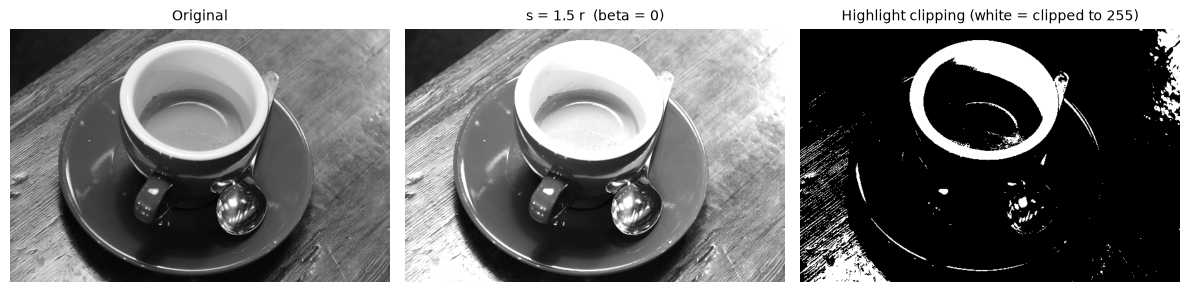

In [6]:
alpha = 1.5
raw2 = alpha * img.astype(np.float64)                 # float64 -> no overflow
contrast0 = to_u8(raw2)                               # clip, then truncate
sat_mask = raw2 > 255                                 # pixels that were clipped to 255

print("Original  :", stats(img))
print("alpha=1.5 :", stats(contrast0))
print(f"Saturated (clipped) pixels: {sat_mask.sum()} = {100*sat_mask.mean():.2f}% of the image  (all r > 170)")

show([img, contrast0, (sat_mask * 255).astype(np.uint8)],
     ["Original", "s = 1.5 r  (beta = 0)", "Highlight clipping (white = clipped to 255)"])

**Observation:** s = 1.5·r multiplies *every* pixel, so the whole image gets brighter (the mean rises, though by less than 50 % because of clipping) *and* contrast increases, but all pixels with r > 170 collapse to 255 — highlight detail is lost.

### Dry run 2 — Linear contrast (pixels = [30, 80, 128, 180, 240])

| r | 1.5·r | clipped | truncated | saturated? |
|---|---|---|---|---|
| 30  | 45.0  | 45  | 45  | no |
| 80  | 120.0 | 120 | 120 | no |
| 128 | 192.0 | 192 | 192 | no |
| 180 | 270.0 | 255 | 255 | **yes** |
| 240 | 360.0 | 255 | 255 | **yes** |

Pixels 180 and 240 are saturated (any r > 170, since 1.5 × 170 = 255); they become identical (255) and can no longer be told apart.

In [7]:
r = np.array([30, 80, 128, 180, 240])
raw = 1.5 * r
clipped = np.clip(raw, 0, 255)
final = clipped.astype(np.uint8)
table(["r", "1.5r", "clipped", "truncated", "saturated?"],
      list(zip(r, raw, clipped, final, raw > 255)))
assert list(final) == [45, 120, 192, 255, 255] and list(raw > 255) == [False, False, False, True, True]
print("Dry run 2 verified.")

r   | 1.5r  | clipped | truncated | saturated?
----+-------+---------+-----------+-----------
30  | 45.0  | 45.0    | 45        | False     
80  | 120.0 | 120.0   | 120       | False     
128 | 192.0 | 192.0   | 192       | False     
180 | 270.0 | 255.0   | 255       | True      
240 | 360.0 | 255.0   | 255       | True      

Dry run 2 verified.


## 3. Contrast centred at 128  ( s = (r − 128)·α + 128 )

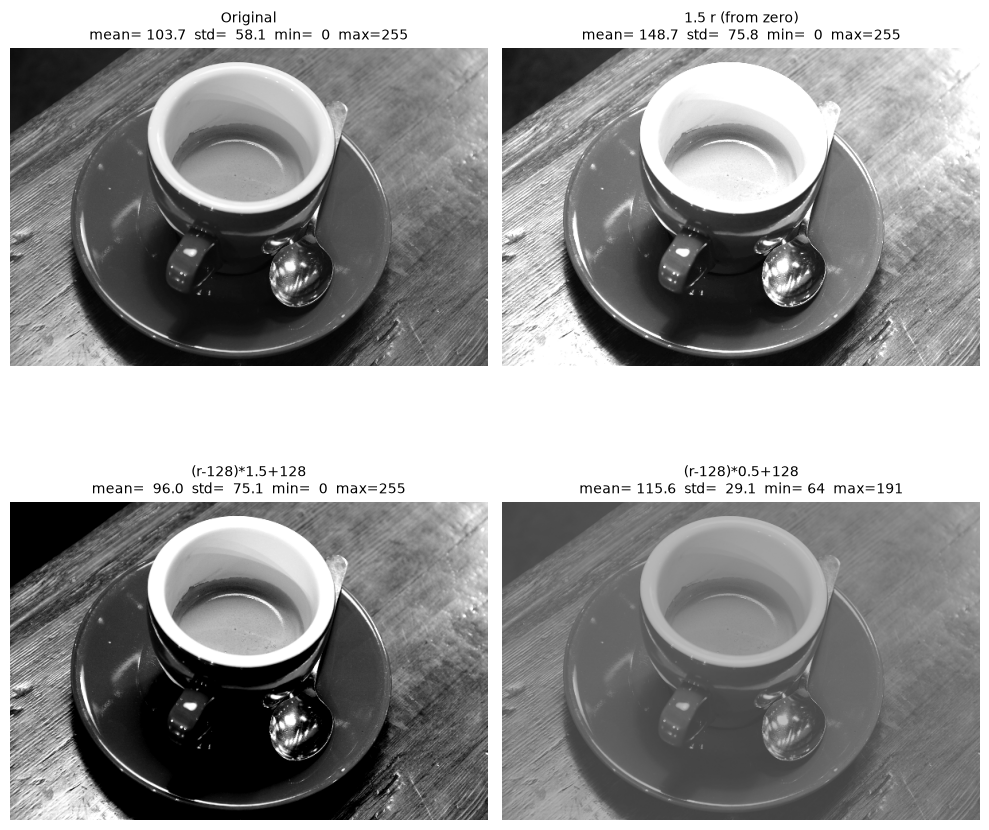

image             | mean  | std  | % at 0 or 255
------------------+-------+------+--------------
original          | 103.7 | 58.1 | 0.00         
1.5 r (from zero) | 148.7 | 75.8 | 12.48        
centred alpha=1.5 | 96.0  | 75.1 | 23.89        
centred alpha=0.5 | 115.6 | 29.1 | 0.00         



In [8]:
def centred_contrast(image, a):
    return to_u8((image.astype(np.float64) - 128.0) * a + 128.0)

c15 = centred_contrast(img, 1.5)
c05 = centred_contrast(img, 0.5)

def clipped_pct(x):  # percentage of pixels at the two extremes
    return 100 * ((x == 0) | (x == 255)).mean()

show([img, contrast0, c15, c05],
     [f"Original\n{stats(img)}",
      f"1.5 r (from zero)\n{stats(contrast0)}",
      f"(r-128)*1.5+128\n{stats(c15)}",
      f"(r-128)*0.5+128\n{stats(c05)}"], ncols=2, size=5)

table(["image", "mean", "std", "% at 0 or 255"],
      [["original", f"{img.mean():.1f}", f"{img.std():.1f}", f"{clipped_pct(img):.2f}"],
       ["1.5 r (from zero)", f"{contrast0.mean():.1f}", f"{contrast0.std():.1f}", f"{clipped_pct(contrast0):.2f}"],
       ["centred alpha=1.5", f"{c15.mean():.1f}", f"{c15.std():.1f}", f"{clipped_pct(c15):.2f}"],
       ["centred alpha=0.5", f"{c05.mean():.1f}", f"{c05.std():.1f}", f"{clipped_pct(c05):.2f}"]])

**Observation:** Centred contrast keeps mid-gray (128) fixed, so it changes *contrast* about the middle without shifting the overall brightness the way 1.5·r does. α = 1.5 stretches (dark pixels get darker, bright ones brighter; both ends may clip), α = 0.5 compresses everything toward gray 128 (flat, washed-out look).

### Dry run 3 — Centred contrast (pixels = [30, 80, 128, 180, 240])

**α = 1.5**

| r | r − 128 | × 1.5 | + 128 | clipped | final |
|---|---|---|---|---|---|
| 30  | −98 | −147 | −19 | 0 | 0 |
| 80  | −48 | −72  | 56  | 56 | 56 |
| 128 | 0   | 0    | 128 | 128 | 128 |
| 180 | 52  | 78   | 206 | 206 | 206 |
| 240 | 112 | 168  | 296 | 255 | 255 |

**α = 0.5**

| r | r − 128 | × 0.5 | + 128 | clipped | final |
|---|---|---|---|---|---|
| 30  | −98 | −49 | 79  | 79  | 79 |
| 80  | −48 | −24 | 104 | 104 | 104 |
| 128 | 0   | 0   | 128 | 128 | 128 |
| 180 | 52  | 26  | 154 | 154 | 154 |
| 240 | 112 | 56  | 184 | 184 | 184 |

**At r = 128:** (128 − 128)·α + 128 = 128 for *any* α, so 128 is the fixed pivot of the transformation.

In [9]:
r = np.array([30, 80, 128, 180, 240])
for a, expected in [(1.5, [0, 56, 128, 206, 255]), (0.5, [79, 104, 128, 154, 184])]:
    d = r - 128; m = d * a; p = m + 128; c = np.clip(p, 0, 255); f = c.astype(np.uint8)
    table(["r", "r-128", f"x{a}", "+128", "clipped", "final"], list(zip(r, d, m, p, c, f)), f"alpha = {a}")
    assert list(f) == expected
print("r = 128 maps to", int(((128 - 128) * 1.5 + 128)), "for alpha=1.5 and", int(((128 - 128) * 0.5 + 128)), "for alpha=0.5")
print("Dry run 3 verified.")

alpha = 1.5
r   | r-128 | x1.5   | +128  | clipped | final
----+-------+--------+-------+---------+------
30  | -98   | -147.0 | -19.0 | 0.0     | 0    
80  | -48   | -72.0  | 56.0  | 56.0    | 56   
128 | 0     | 0.0    | 128.0 | 128.0   | 128  
180 | 52    | 78.0   | 206.0 | 206.0   | 206  
240 | 112   | 168.0  | 296.0 | 255.0   | 255  

alpha = 0.5
r   | r-128 | x0.5  | +128  | clipped | final
----+-------+-------+-------+---------+------
30  | -98   | -49.0 | 79.0  | 79.0    | 79   
80  | -48   | -24.0 | 104.0 | 104.0   | 104  
128 | 0     | 0.0   | 128.0 | 128.0   | 128  
180 | 52    | 26.0  | 154.0 | 154.0   | 154  
240 | 112   | 56.0  | 184.0 | 184.0   | 184  

r = 128 maps to 128 for alpha=1.5 and 128 for alpha=0.5
Dry run 3 verified.


## 4. Image negative  ( s = 255 − r )

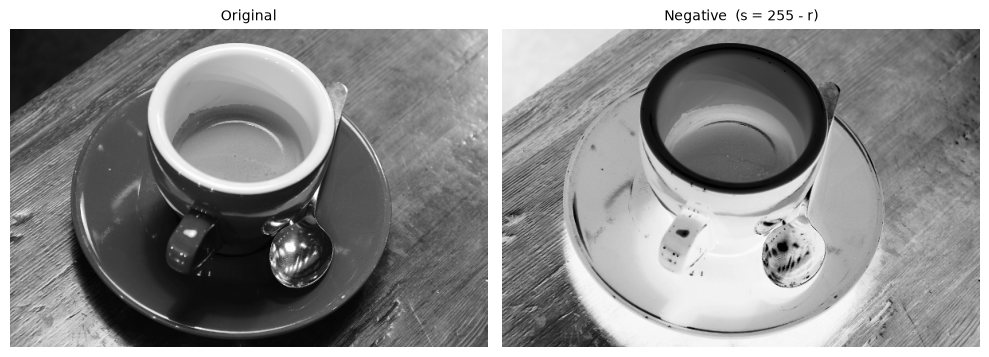

Applying the negative twice gives back the original: True


In [10]:
negative = to_u8(255 - img.astype(np.int16))
show([img, negative], ["Original", "Negative  (s = 255 - r)"], size=5)
print("Applying the negative twice gives back the original:", np.array_equal(to_u8(255 - negative.astype(np.int16)), img))

**When is it useful?** In medical imaging (e.g. X-rays, mammograms) or any image with bright, large background areas, fine *light/white* details on a *dark* background are easier for the eye to see when inverted, because humans discriminate small intensity differences in dark regions better than in bright ones.

### Dry run 4 — Negative (pixels = [30, 80, 128, 180, 240])

| r | 255 − r | negative again: 255 − (255 − r) | equals original? |
|---|---|---|---|
| 30  | 225 | 30  | ✔ |
| 80  | 175 | 80  | ✔ |
| 128 | 127 | 128 | ✔ |
| 180 | 75  | 180 | ✔ |
| 240 | 15  | 240 | ✔ |

The negative is its own inverse: 255 − (255 − r) = r.

In [11]:
r = np.array([30, 80, 128, 180, 240])
neg = 255 - r
neg2 = 255 - neg
table(["r", "255-r", "255-(255-r)", "same as original"], list(zip(r, neg, neg2, neg2 == r)))
assert list(neg) == [225, 175, 127, 75, 15] and np.array_equal(neg2, r)
print("Dry run 4 verified.")

r   | 255-r | 255-(255-r) | same as original
----+-------+-------------+-----------------
30  | 225   | 30          | True            
80  | 175   | 80          | True            
128 | 127   | 128         | True            
180 | 75    | 180         | True            
240 | 15    | 240         | True            

Dry run 4 verified.


## 5. Gamma correction  ( s = 255·(r/255)^γ,  γ = 0.5 and 2.0 )
Convention used in this lab: **γ is applied directly as the exponent**. γ < 1 brightens (expands dark values), γ > 1 darkens (compresses dark values). Full precision is kept; only the final result is truncated.

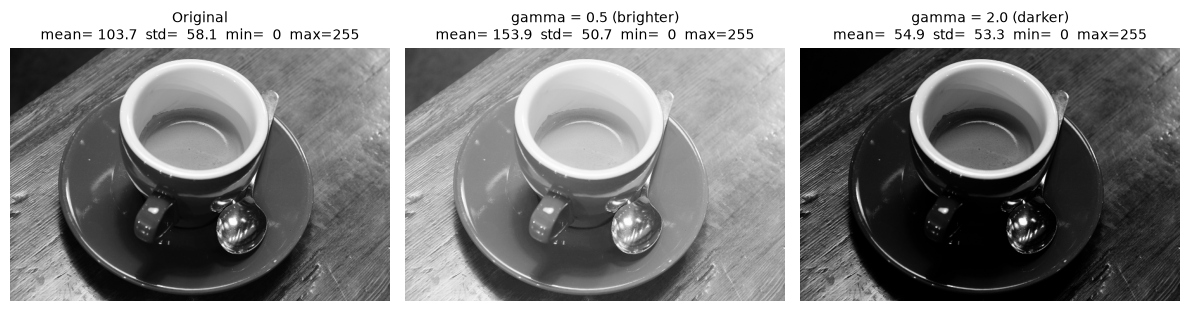

Dark region = 24.5% of the pixels (r < 64)
  mean in that region  original:  28.20   gamma 0.5:  80.62   gamma 2.0:   3.70
gamma=0.5: [0, 255] -> [0, 255]
gamma=2.0: [0, 255] -> [0, 255]


In [12]:
def gamma_correct(image, g):
    return to_u8(255.0 * (image.astype(np.float64) / 255.0) ** g)

g05 = gamma_correct(img, 0.5)
g20 = gamma_correct(img, 2.0)

show([img, g05, g20],
     [f"Original\n{stats(img)}", f"gamma = 0.5 (brighter)\n{stats(g05)}", f"gamma = 2.0 (darker)\n{stats(g20)}"])

# effect on DARK regions (original pixels below 64)
dark_region = img < 64
print(f"Dark region = {100*dark_region.mean():.1f}% of the pixels (r < 64)")
print(f"  mean in that region  original: {img[dark_region].mean():6.2f}   gamma 0.5: {g05[dark_region].mean():6.2f}   gamma 2.0: {g20[dark_region].mean():6.2f}")

# 0 and 255 stay fixed
ends = np.array([0, 255], dtype=np.uint8)
for g in (0.5, 2.0):
    print(f"gamma={g}: [0, 255] -> {gamma_correct(ends, g).tolist()}")
    assert gamma_correct(ends, g).tolist() == [0, 255]

**Observation:** γ = 0.5 lifts the dark region strongly (shadow detail becomes visible, image looks washed-out in brighter parts); γ = 2.0 pushes dark values even lower and keeps only the brightest areas bright. Black (0) and white (255) never move, so gamma does **not** clip.

### Dry run 5 — Gamma (pixels = [0, 64, 128, 192, 255])
Full precision is kept: normalise → power → scale → truncate.

**γ = 0.5**

| r | r/255 | (r/255)^0.5 | ×255 | truncated |
|---|---|---|---|---|
| 0   | 0.000000 | 0.000000 | 0.0000   | 0 |
| 64  | 0.250980 | 0.500979 | 127.7498 | 127 |
| 128 | 0.501961 | 0.708492 | 180.6654 | 180 |
| 192 | 0.752941 | 0.867722 | 221.2691 | 221 |
| 255 | 1.000000 | 1.000000 | 255.0000 | 255 |

**γ = 2.0**

| r | r/255 | (r/255)^2 | ×255 | truncated |
|---|---|---|---|---|
| 0   | 0.000000 | 0.000000 | 0.0000   | 0 |
| 64  | 0.250980 | 0.062991 | 16.0627  | 16 |
| 128 | 0.501961 | 0.251965 | 64.2510  | 64 |
| 192 | 0.752941 | 0.566920 | 144.5647 | 144 |
| 255 | 1.000000 | 1.000000 | 255.0000 | 255 |

**Difference from a rounded slide example:** a slide that rounds r/255 to 0.25, 0.50, 0.75 (instead of 64/255 = 0.25098, 128/255 = 0.50196, 192/255 = 0.75294) gets 127, 180, **220** for γ = 0.5 and **15, 63, 143** for γ = 2.0. Rounding the normalised value early changes the result by about one gray level; keeping full precision gives 127, 180, 221 and 16, 64, 144.

In [13]:
r = np.array([0, 64, 128, 192, 255])
for g, expected in [(0.5, [0, 127, 180, 221, 255]), (2.0, [0, 16, 64, 144, 255])]:
    n = r / 255; p = n ** g; s = 255 * p; f = s.astype(np.uint8)
    table(["r", "r/255", f"(r/255)^{g}", "x255", "truncated"],
          [[a, f"{b:.6f}", f"{c:.6f}", f"{d:.4f}", e] for a, b, c, d, e in zip(r, n, p, s, f)], f"gamma = {g}")
    assert list(f) == expected

# the 'rounded slide' version: r/255 rounded to 2 decimals first
for g in (0.5, 2.0):
    n = np.round(r / 255, 2); s = 255 * n ** g
    print(f"rounded-normalisation (gamma={g}): normalised={n.tolist()} -> x255={np.round(s, 2).tolist()} -> truncated={s.astype(int).tolist()}")
print("Dry run 5 verified.")

gamma = 0.5
r   | r/255    | (r/255)^0.5 | x255     | truncated
----+----------+-------------+----------+----------
0   | 0.000000 | 0.000000    | 0.0000   | 0        
64  | 0.250980 | 0.500979    | 127.7498 | 127      
128 | 0.501961 | 0.708492    | 180.6654 | 180      
192 | 0.752941 | 0.867722    | 221.2691 | 221      
255 | 1.000000 | 1.000000    | 255.0000 | 255      

gamma = 2.0
r   | r/255    | (r/255)^2.0 | x255     | truncated
----+----------+-------------+----------+----------
0   | 0.000000 | 0.000000    | 0.0000   | 0        
64  | 0.250980 | 0.062991    | 16.0627  | 16       
128 | 0.501961 | 0.251965    | 64.2510  | 64       
192 | 0.752941 | 0.566920    | 144.5647 | 144      
255 | 1.000000 | 1.000000    | 255.0000 | 255      

rounded-normalisation (gamma=0.5): normalised=[0.0, 0.25, 0.5, 0.75, 1.0] -> x255=[0.0, 127.5, 180.31, 220.84, 255.0] -> truncated=[0, 127, 180, 220, 255]
rounded-normalisation (gamma=2.0): normalised=[0.0, 0.25, 0.5, 0.75, 1.0] -> x255=[0.0, 15.

## 6. Grayscale histogram (256 bins, range 0–256)

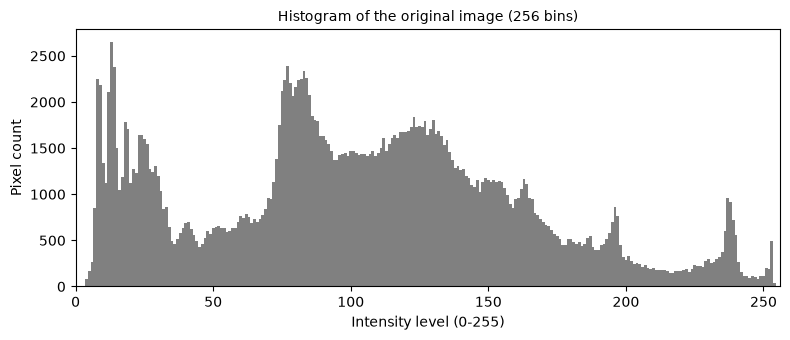

1) The histogram has a mean of 103.7 and a standard deviation of 58.1, so the image is overall mid-toned.
2) 24.5% of the pixels are darker than 64 and 7.6% are brighter than 192, and the occupied range (0-255) is nearly the full 0-255 range.


In [14]:
hist = hist256(img)
assert hist.sum() == img.size            # every pixel is counted exactly once

plt.figure(figsize=(8, 3.5))
plt.bar(np.arange(256), hist, width=1.0, color="gray")
plt.xlim(0, 256)
plt.xlabel("Intensity level (0-255)"); plt.ylabel("Pixel count")
plt.title("Histogram of the original image (256 bins)")
plt.tight_layout(); plt.show()

# two-sentence interpretation generated from the image statistics
mean, std = img.mean(), img.std()
p_dark, p_bright = 100 * (img < 64).mean(), 100 * (img > 192).mean()
tone = "dark" if mean < 85 else ("bright" if mean > 170 else "mid-toned")
rng = int(img.max()) - int(img.min())
print(f"1) The histogram has a mean of {mean:.1f} and a standard deviation of {std:.1f}, so the image is overall {tone}.")
print(f"2) {p_dark:.1f}% of the pixels are darker than 64 and {p_bright:.1f}% are brighter than 192, and the occupied range "
      f"({int(img.min())}-{int(img.max())}) is {'nearly the full' if rng > 200 else 'only part of the'} 0-255 range.")

### Dry run 6 — Histogram of A = [[0, 50, 50, 100], [100, 150, 200, 255]]

Total pixel count = 2 × 4 = **8**

| intensity | frequency | probability = freq / 8 |
|---|---|---|
| 0   | 1 | 0.125 |
| 50  | 2 | 0.250 |
| 100 | 2 | 0.250 |
| 150 | 1 | 0.125 |
| 200 | 1 | 0.125 |
| 255 | 1 | 0.125 |
| **Total** | **8** | **1.000** |

**Why a histogram does not show positions:** it only *counts* how many pixels have each intensity. Any rearrangement of the same pixels (shuffling, flipping, rotating) gives exactly the same histogram, so spatial information is thrown away.

In [15]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
vals, freq = np.unique(A, return_counts=True)
prob = freq / A.size
table(["intensity", "frequency", "probability"], list(zip(vals, freq, prob)))
print("Total pixels:", A.size, "| sum of probabilities:", prob.sum())
assert A.size == 8 and freq.tolist() == [1, 2, 2, 1, 1, 1] and np.isclose(prob.sum(), 1.0)

# same histogram, completely different arrangement
rng_ = np.random.default_rng(0)
B = rng_.permutation(A.ravel()).reshape(A.shape)
print("A:\n", A, "\nShuffled copy B:\n", B)
print("Histograms identical:", np.array_equal(np.bincount(A.ravel(), minlength=256), np.bincount(B.ravel(), minlength=256)))
print("Dry run 6 verified.")

intensity | frequency | probability
----------+-----------+------------
0         | 1         | 0.125      
50        | 2         | 0.25       
100       | 2         | 0.25       
150       | 1         | 0.125      
200       | 1         | 0.125      
255       | 1         | 0.125      

Total pixels: 8 | sum of probabilities: 1.0
A:
 [[  0  50  50 100]
 [100 150 200 255]] 
Shuffled copy B:
 [[ 50 100 100 200]
 [150   0  50 255]]
Histograms identical: True
Dry run 6 verified.


## 7. Global histogram equalization (`cv2.equalizeHist`)

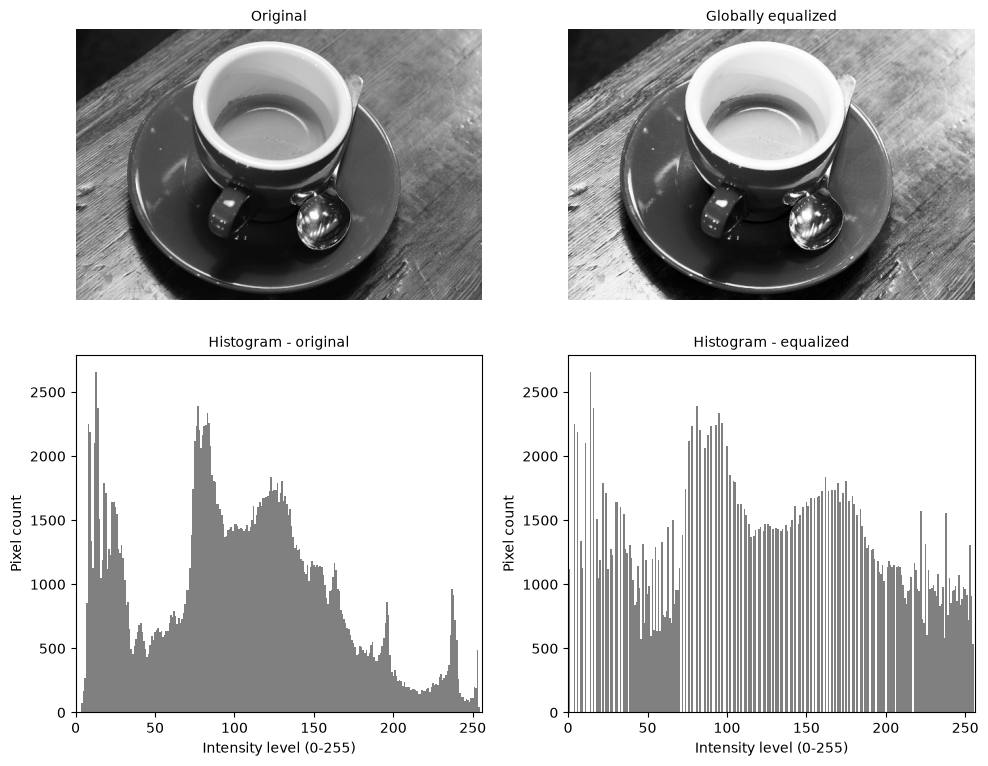

Original : mean= 103.7  std=  58.1  min=  0  max=255
Equalized: mean= 128.2  std=  73.5  min=  0  max=255

Smoothest block at (row 320, col 256):  std original = 0.64   std equalized = 1.71
Mean |Laplacian| (fine-detail + noise energy): original = 19.51, equalized = 27.47


In [16]:
eq = cv2.equalizeHist(img)

fig, ax = plt.subplots(2, 2, figsize=(10, 8))
ax[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); ax[0, 0].set_title("Original"); ax[0, 0].axis("off")
ax[0, 1].imshow(eq,  cmap="gray", vmin=0, vmax=255); ax[0, 1].set_title("Globally equalized"); ax[0, 1].axis("off")
plot_hist(ax[1, 0], img, "Histogram - original")
plot_hist(ax[1, 1], eq,  "Histogram - equalized")
plt.tight_layout(); plt.show()

print("Original :", stats(img))
print("Equalized:", stats(eq))

# noise check: smoothest (flat) 16x16 block, std measures texture/noise there
fi, fj = flattest_block(img)
blk = lambda x: x[fi:fi+16, fj:fj+16]
print(f"\nSmoothest block at (row {fi}, col {fj}):  std original = {blk(img).std():.2f}   std equalized = {blk(eq).std():.2f}")
print(f"Mean |Laplacian| (fine-detail + noise energy): original = {np.abs(cv2.Laplacian(img, cv2.CV_64F)).mean():.2f}, "
      f"equalized = {np.abs(cv2.Laplacian(eq, cv2.CV_64F)).mean():.2f}")

**Discussion:** Equalization spreads the occupied gray levels over the full 0–255 range, so overall contrast and visible detail increase, especially where levels were crowded together. Because the same mapping is applied to the *whole* image, bright or dark areas can look over-enhanced, and the stretch also magnifies small differences in smooth regions — the flat-block standard deviation and Laplacian energy above show that **noise becomes stronger**.

### Dry run 7 — Equalization of pixels [50, 50, 100, 150]  (N = 4)

| level | frequency | cumulative count | CDF |
|---|---|---|---|
| 50  | 2 | 2 | 0.50 |
| 100 | 1 | 3 | 0.75 |
| 150 | 1 | 4 | 1.00 |

**Method 1 — 255 × CDF** (round to nearest, .5 up): 50 → 127.5 → **128**, 100 → 191.25 → **191**, 150 → 255. Output: **[128, 128, 191, 255]**

**Method 2 — 255 × (CDF − CDFmin)/(1 − CDFmin)**, CDFmin = 0.50: (0, 0.5, 1) → 50 → **0**, 100 → 127.5 → **128**, 150 → **255**. Output: **[0, 0, 128, 255]**

OpenCV returns [0, 0, 128, 255] — identical to Method 2. Method 1 never maps the darkest level to 0, so part of the output range is wasted; Method 2 subtracts CDFmin so the darkest level becomes 0.

In [17]:
px = np.array([50, 50, 100, 150])
levels, freq = np.unique(px, return_counts=True)
cum = np.cumsum(freq); cdf = cum / px.size
table(["level", "freq", "cum. count", "CDF"], list(zip(levels, freq, cum, cdf)))

half_up = lambda x: np.floor(x + 0.5).astype(int)                 # round to nearest, .5 upward
m1 = half_up(255 * cdf)
cdf_min = cdf[cdf > 0].min()
m2 = half_up(255 * (cdf - cdf_min) / (1 - cdf_min))

out1 = [int(dict(zip(levels, m1))[p]) for p in px]
out2 = [int(dict(zip(levels, m2))[p]) for p in px]
cv_out = cv2.equalizeHist(px.astype(np.uint8).reshape(1, -1)).ravel().tolist()

print("CDFmin           :", cdf_min)
print("Method 1 output  :", out1)
print("Method 2 output  :", out2)
print("OpenCV output    :", cv_out)
assert out1 == [128, 128, 191, 255] and out2 == [0, 0, 128, 255] and cv_out == out2
print("Dry run 7 verified (Method 2 == OpenCV).")

level | freq | cum. count | CDF 
------+------+------------+-----
50    | 2    | 2          | 0.5 
100   | 1    | 3          | 0.75
150   | 1    | 4          | 1.0 

CDFmin           : 0.5
Method 1 output  : [128, 128, 191, 255]
Method 2 output  : [0, 0, 128, 255]
OpenCV output    : [0, 0, 128, 255]
Dry run 7 verified (Method 2 == OpenCV).


## 8. CLAHE (`clipLimit = 2.0`, `tileGridSize = (8, 8)`)
`(8, 8)` is the **number of tiles** (8 rows × 8 columns), *not* the number of pixels per tile.

Image 400x600 with an 8x8 tile grid -> each tile is about 50 x 75 pixels


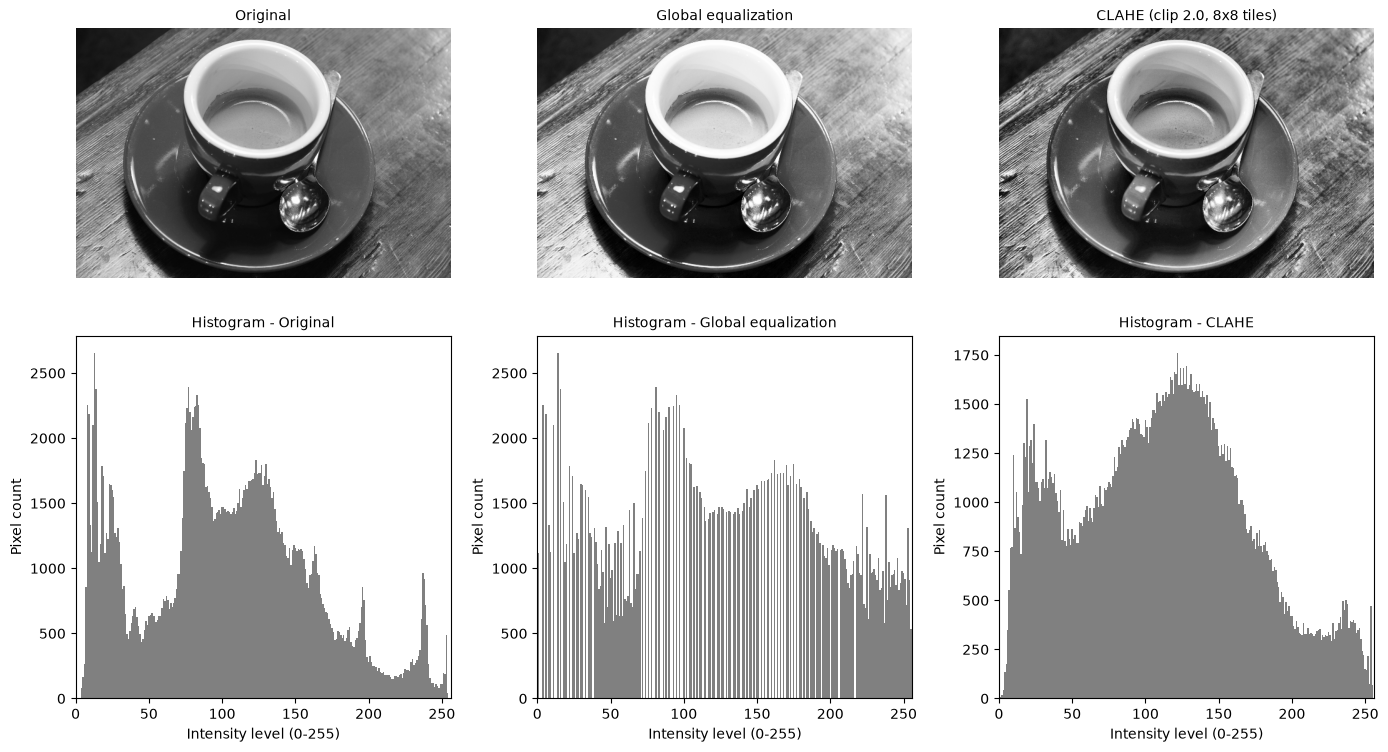

image     | top-left  (mean / std) | top-right  (mean / std) | bottom-left  (mean / std) | bottom-right  (mean / std)
----------+------------------------+-------------------------+---------------------------+---------------------------
original  | 110.8 /  57.1          | 144.8 /  39.8           |  79.4 /  63.6             |  79.6 /  41.4             
global HE | 135.6 /  69.3          | 185.0 /  44.5           |  96.2 /  81.5             |  96.1 /  53.2             
CLAHE     | 112.2 /  61.7          | 138.3 /  45.8           |  91.7 /  63.9             | 103.2 /  53.5             

Smoothest block (row 320, col 256) std:  original 0.64 | global HE 1.71 | CLAHE 1.57
Mean |Laplacian|:  original 19.51 | global HE 27.47 | CLAHE 35.95


In [18]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
cl = clahe.apply(img)

print(f"Image {img.shape[0]}x{img.shape[1]} with an 8x8 tile grid -> each tile is about {img.shape[0]//8} x {img.shape[1]//8} pixels")

fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for k, (im, t) in enumerate([(img, "Original"), (eq, "Global equalization"), (cl, "CLAHE (clip 2.0, 8x8 tiles)")]):
    ax[0, k].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, k].set_title(t); ax[0, k].axis("off")
    plot_hist(ax[1, k], im, "Histogram - " + t.split(" (")[0])
plt.tight_layout(); plt.show()

# uneven lighting: local contrast (std) and brightness (mean) in each quadrant
names = ["top-left", "top-right", "bottom-left", "bottom-right"]
rows = []
for label, im in [("original", img), ("global HE", eq), ("CLAHE", cl)]:
    q = quadrant(im)
    rows.append([label] + [f"{x.mean():5.1f} / {x.std():5.1f}" for x in q])
table(["image"] + [n + "  (mean / std)" for n in names], rows)

print(f"Smoothest block (row {fi}, col {fj}) std:  original {blk(img).std():.2f} | global HE {blk(eq).std():.2f} | CLAHE {blk(cl).std():.2f}")
print(f"Mean |Laplacian|:  original {np.abs(cv2.Laplacian(img, cv2.CV_64F)).mean():.2f} | global HE {np.abs(cv2.Laplacian(eq, cv2.CV_64F)).mean():.2f} | CLAHE {np.abs(cv2.Laplacian(cl, cv2.CV_64F)).mean():.2f}")

**Comparison:** Global equalization uses one mapping for the whole image, so under uneven lighting a dark region and a bright region are both forced onto the same curve. CLAHE equalizes each tile separately, so *local* contrast improves in both dark and bright areas. In the quadrant table above, global equalization pushes the already-bright top-right quadrant much brighter (for the supplied sample image: mean 144.8 → 185.0, a risk of washed-out highlights), while CLAHE keeps it close to the original (→ 138.3) and still raises its local contrast (std 39.8 → 45.8), i.e. CLAHE copes better with uneven lighting. The clip limit caps how steep each tile's mapping can be, which limits noise amplification *compared with unclipped adaptive equalization*; however, the smooth-block standard deviation and Laplacian energy above show that CLAHE still raises fine-detail/noise energy, so it is a trade-off between local detail and noise.

### Dry run 8 — Simplified CLAHE clipping, histogram [6, 2, 0, 0], absolute cap = 4

| step | bin 0 | bin 1 | bin 2 | bin 3 | total |
|---|---|---|---|---|---|
| original counts | 6 | 2 | 0 | 0 | 8 |
| clip at 4 | 4 | 2 | 0 | 0 | 6 (excess = 2) |
| add excess/4 = 0.5 to every bin | 4.5 | 2.5 | 0.5 | 0.5 | 8 |
| cumulative count | 4.5 | 7.0 | 7.5 | 8.0 | |
| **new CDF** | **0.5625** | **0.8750** | **0.9375** | **1.0000** | |
| ×255 mapping | 143.4 | 223.1 | 239.1 | 255 | |

Without clipping the CDF would be [0.75, 1, 1, 1] (×255 → 191, 255, 255, 255): the dominant bin gets a very steep jump. Clipping flattens that slope and limits contrast/noise amplification.

**Why interpolation is needed:** every tile has its *own* mapping function. If each pixel used only its own tile's mapping, neighbouring tiles would map the same gray level to different values and visible block edges would appear. OpenCV therefore bilinearly interpolates between the mappings of the neighbouring tiles.

*Note:* this model uses an absolute cap and fractional redistribution; OpenCV's `clipLimit` is a *relative* factor (scaled by tile size / number of bins) and redistributes integers, so results differ slightly.

In [19]:
hist4 = np.array([6, 2, 0, 0], dtype=float)
cap = 4
clipped_h = np.minimum(hist4, cap)
excess = (hist4 - clipped_h).sum()
redistributed = clipped_h + excess / hist4.size
cdf_new = np.cumsum(redistributed) / redistributed.sum()
cdf_old = np.cumsum(hist4) / hist4.sum()

print("clipped            :", clipped_h, "| excess =", excess)
print("after redistribute :", redistributed, "| total =", redistributed.sum())
print("new CDF            :", cdf_new, "-> x255:", np.round(255 * cdf_new, 1))
print("CDF without clip   :", cdf_old, "-> x255:", np.round(255 * cdf_old, 1))
assert redistributed.tolist() == [4.5, 2.5, 0.5, 0.5] and np.allclose(cdf_new, [0.5625, 0.875, 0.9375, 1.0])
print("Dry run 8 verified.")

clipped            : [4. 2. 0. 0.] | excess = 2.0
after redistribute : [4.5 2.5 0.5 0.5] | total = 8.0
new CDF            : [0.5625 0.875  0.9375 1.    ] -> x255: [143.4 223.1 239.1 255. ]
CDF without clip   : [0.75 1.   1.   1.  ] -> x255: [191.2 255.  255.  255. ]
Dry run 8 verified.


## 9. Fixed binary thresholding (`cv2.THRESH_BINARY`, T = 127)

Threshold used  : 127.0
Unique values   : [0, 255]
White pixels    : 80304 (33.5%)


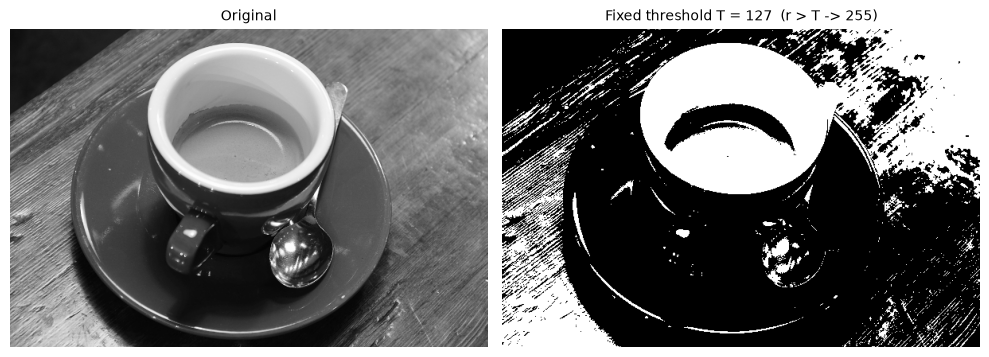

In [20]:
T_fixed, bin127 = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
print("Threshold used  :", T_fixed)
print("Unique values   :", np.unique(bin127).tolist())
print(f"White pixels    : {(bin127 == 255).sum()} ({100*(bin127 == 255).mean():.1f}%)")
show([img, bin127], ["Original", "Fixed threshold T = 127  (r > T -> 255)"], size=5)

### Dry run 9 — Fixed threshold (pixels = [0, 80, 127, 128, 180, 255])  rule: output 255 if r > T else 0

| r | T = 127 | T = 180 |
|---|---|---|
| 0   | 0   | 0 |
| 80  | 0   | 0 |
| 127 | 0 (127 > 127 is false) | 0 |
| 128 | 255 | 0 |
| 180 | 255 | 0 (180 > 180 is false) |
| 255 | 255 | 255 |
| **white pixels** | **3** | **1** |

Raising T from 127 to 180 shrinks the white set from 3 pixels to 1.

In [21]:
px = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
res = {}
for T in (127, 180):
    mine = np.where(px > T, 255, 0).astype(np.uint8)
    _, cv_res = cv2.threshold(px.reshape(1, -1), T, 255, cv2.THRESH_BINARY)
    assert np.array_equal(mine, cv_res.ravel())
    res[T] = mine
table(["r", "T=127", "T=180"], list(zip(px, res[127], res[180])))
print("White pixels  T=127:", int((res[127] == 255).sum()), "| T=180:", int((res[180] == 255).sum()))
assert (res[127] == 255).sum() == 3 and (res[180] == 255).sum() == 1
print("Dry run 9 verified (matches OpenCV).")

r   | T=127 | T=180
----+-------+------
0   | 0     | 0    
80  | 0     | 0    
127 | 0     | 0    
128 | 255   | 0    
180 | 255   | 0    
255 | 255   | 255  

White pixels  T=127: 3 | T=180: 1
Dry run 9 verified (matches OpenCV).


## 10. Otsu thresholding (`THRESH_BINARY + THRESH_OTSU`)

Otsu threshold returned by OpenCV: 105.0
Unique values: [0, 255]
Fixed T=127 vs Otsu T=105: 35419 pixels differ (14.76%)
White pixels  fixed: 33.5%   Otsu: 48.2%


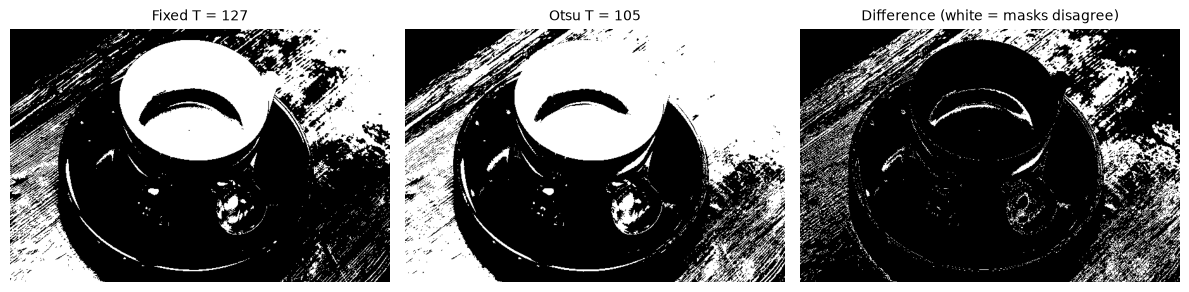

In [22]:
T_otsu, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold returned by OpenCV:", T_otsu)
print("Unique values:", np.unique(otsu).tolist())

diff = (otsu != bin127)
print(f"Fixed T=127 vs Otsu T={T_otsu:.0f}: {diff.sum()} pixels differ ({100*diff.mean():.2f}%)")
print(f"White pixels  fixed: {100*(bin127 == 255).mean():.1f}%   Otsu: {100*(otsu == 255).mean():.1f}%")

show([bin127, otsu, (diff * 255).astype(np.uint8)],
     ["Fixed T = 127", f"Otsu T = {T_otsu:.0f}", "Difference (white = masks disagree)"])

**Comparison:** Otsu chooses the threshold automatically by maximising the between-class variance, so it adapts to the histogram of *this* image, whereas T = 127 is arbitrary. The difference image shows exactly where the two masks disagree (pixels between the two thresholds).

### Dry run 10 — Otsu on pixels [0, 1, 4, 5] (no rescaling)  N = 4
Classes: class 0 = r ≤ T, class 1 = r > T.  Criterion: w0·w1·(μ0 − μ1)²

| T | class 0 | class 1 | w0 | w1 | μ0 | μ1 | w0·w1·(μ0−μ1)² |
|---|---|---|---|---|---|---|---|
| 0 | {0} | {1, 4, 5} | 0.25 | 0.75 | 0 | 3.3333 | 0.25·0.75·(−3.3333)² = **2.0833** |
| 1 | {0, 1} | {4, 5} | 0.50 | 0.50 | 0.5 | 4.5 | 0.5·0.5·(−4)² = **4.0000** |
| 2 | {0, 1} | {4, 5} | 0.50 | 0.50 | 0.5 | 4.5 | **4.0000** |
| 3 | {0, 1} | {4, 5} | 0.50 | 0.50 | 0.5 | 4.5 | **4.0000** |
| 4 | {0, 1, 4} | {5} | 0.75 | 0.25 | 1.6667 | 5 | 0.75·0.25·(−3.3333)² = **2.0833** |

The maximum (4.0) is tied for T = 1, 2, 3 → choose the **smallest, T = 1**.
Predicted mask (r > 1): **[0, 0, 255, 255]**. OpenCV returns threshold 1.0 and the same mask.

In [23]:
px = np.array([0, 1, 4, 5])
rows, scores = [], {}
for T in range(0, 5):
    c0, c1 = px[px <= T], px[px > T]
    w0, w1 = len(c0) / px.size, len(c1) / px.size
    mu0, mu1 = c0.mean(), c1.mean()
    scores[T] = w0 * w1 * (mu0 - mu1) ** 2
    rows.append([T, c0.tolist(), c1.tolist(), w0, w1, round(mu0, 4), round(mu1, 4), round(scores[T], 4)])
table(["T", "class0", "class1", "w0", "w1", "mu0", "mu1", "w0*w1*(mu0-mu1)^2"], rows)

best = max(scores.values())
T_best = min(T for T, s in scores.items() if np.isclose(s, best))        # smallest T among ties
pred_mask = np.where(px > T_best, 255, 0).astype(np.uint8)
cv_T, cv_mask = cv2.threshold(px.astype(np.uint8).reshape(1, -1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Best T (smallest among ties):", T_best, "| predicted mask:", pred_mask.tolist())
print("OpenCV threshold            :", cv_T, "| OpenCV mask:", cv_mask.ravel().tolist())
assert T_best == 1 and pred_mask.tolist() == [0, 0, 255, 255] and cv_mask.ravel().tolist() == pred_mask.tolist()
print("Dry run 10 verified.")

T | class0    | class1    | w0   | w1   | mu0    | mu1    | w0*w1*(mu0-mu1)^2
--+-----------+-----------+------+------+--------+--------+------------------
0 | [0]       | [1, 4, 5] | 0.25 | 0.75 | 0.0    | 3.3333 | 2.0833           
1 | [0, 1]    | [4, 5]    | 0.5  | 0.5  | 0.5    | 4.5    | 4.0              
2 | [0, 1]    | [4, 5]    | 0.5  | 0.5  | 0.5    | 4.5    | 4.0              
3 | [0, 1]    | [4, 5]    | 0.5  | 0.5  | 0.5    | 4.5    | 4.0              
4 | [0, 1, 4] | [5]       | 0.75 | 0.25 | 1.6667 | 5.0    | 2.0833           

Best T (smallest among ties): 1 | predicted mask: [0, 0, 255, 255]
OpenCV threshold            : 1.0 | OpenCV mask: [0, 0, 255, 255]
Dry run 10 verified.


## 11. Adaptive Gaussian thresholding (`blockSize = 11`, `C = 2`)

Unique values: [0, 255]
White pixels  fixed: 33.5%  Otsu: 48.2%  adaptive: 64.5%
Adaptive agrees with Otsu on 56.1% of the pixels, with fixed T=127 on 54.0%


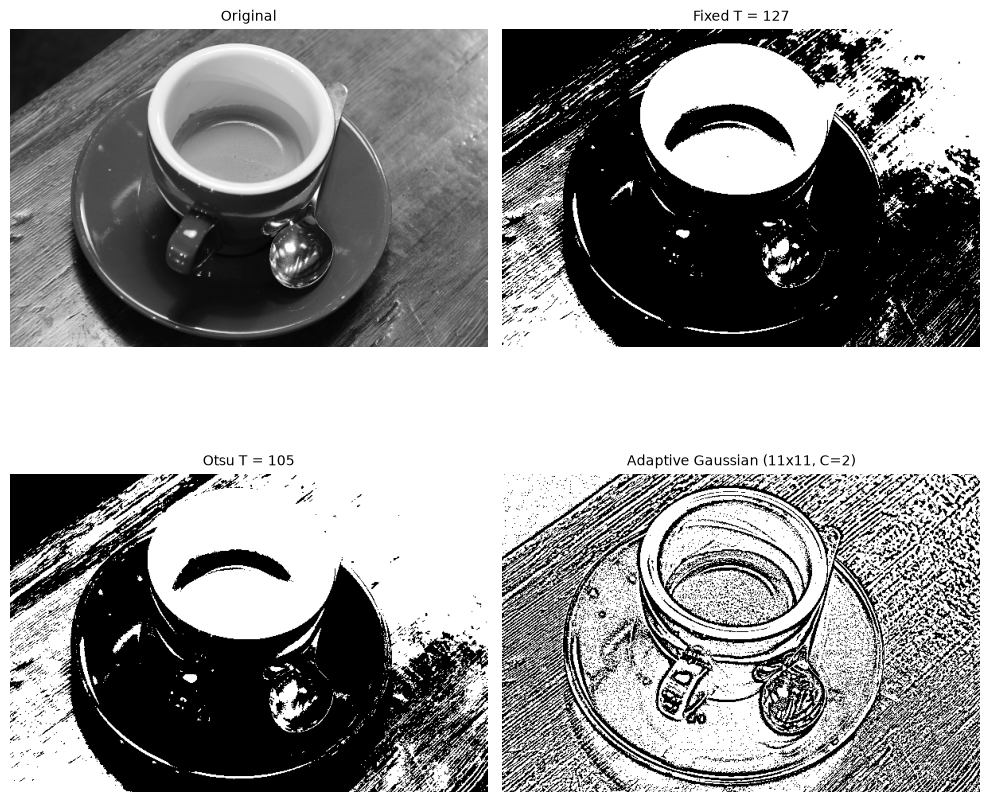

In [24]:
adaptive = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)
print("Unique values:", np.unique(adaptive).tolist())
print(f"White pixels  fixed: {100*(bin127 == 255).mean():.1f}%  Otsu: {100*(otsu == 255).mean():.1f}%  adaptive: {100*(adaptive == 255).mean():.1f}%")
print(f"Adaptive agrees with Otsu on {100*(adaptive == otsu).mean():.1f}% of the pixels, with fixed T=127 on {100*(adaptive == bin127).mean():.1f}%")

show([img, bin127, otsu, adaptive],
     ["Original", "Fixed T = 127", f"Otsu T = {T_otsu:.0f}", "Adaptive Gaussian (11x11, C=2)"], ncols=2, size=5)

**Comparison:** Fixed and Otsu thresholds use *one* value for the entire image, so they fail when lighting is uneven (a shadowed object falls entirely below T). The adaptive method computes a different threshold for every pixel from its 11 × 11 Gaussian-weighted neighbourhood (T = local mean − C), so it follows local brightness and brings out edges and fine structure. Local thresholds help for uneven illumination, shadows, document scans; the downside is noise-like speckle in flat regions (where the pixel is within ±C of the local mean) and that large uniform areas are not filled consistently.

### Dry run 11 — Adaptive Gaussian threshold (3 × 3 example)
Neighbourhood [[100, 100, 100], [100, 120, 140], [140, 140, 140]], weights [[1, 2, 1], [2, 4, 2], [1, 2, 1]] / 16.

Weighted sum = 1·100 + 2·100 + 1·100 + 2·100 + 4·120 + 2·140 + 1·140 + 2·140 + 1·140 = 400 + 960 + 560 = **1920**
Weighted mean = 1920 / 16 = **120**;  T = mean − C = 120 − 2 = **118**

* Centre pixel r = 120: 120 > 118 → **255 (white)**
* A pixel equal to T (r = 118): 118 > 118 is false → **0 (black)** (equality goes to the background)

In [25]:
nb = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]], dtype=float)
wts = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16
C = 2
weighted_sum = (nb * wts).sum()                 # = weighted mean because weights sum to 1
T_local = weighted_sum - C
centre = nb[1, 1]
print("Weights sum        :", wts.sum())
print("Weighted mean      :", weighted_sum)
print("T = mean - C       :", T_local)
print("Centre pixel", centre, "->", 255 if centre > T_local else 0)
print("Pixel equal to T (", T_local, ") ->", 255 if T_local > T_local else 0)
assert weighted_sum == 120 and T_local == 118 and (centre > T_local) and not (T_local > T_local)

# cross-check the centre pixel with OpenCV on the same 3x3 patch (blockSize=3 -> same 1-2-1 kernel)
cv_patch = cv2.adaptiveThreshold(nb.astype(np.uint8), 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, 2)
print("OpenCV centre pixel:", cv_patch[1, 1])
assert cv_patch[1, 1] == 255
print("Dry run 11 verified.")

Weights sum        : 1.0
Weighted mean      : 120.0
T = mean - C       : 118.0
Centre pixel 120.0 -> 255
Pixel equal to T ( 118.0 ) -> 0
OpenCV centre pixel: 255
Dry run 11 verified.


## Concept summary

**Clipping vs overflow.** Overflow is *wrap-around*: in `uint8`, 250 + 40 = 290 becomes 34 (290 mod 256), turning a bright pixel dark. Clipping (saturation) is the safe alternative: do arithmetic in a wider type (`int16`/`float64`), force results into 0–255 with `np.clip`, then convert to `uint8` (fractions are truncated). Clipping loses detail (many values collapse to 0 or 255) but never produces false values.

**Brightness vs contrast.** Brightness (s = r + β) *shifts* all intensities up/down; the spread (contrast) is unchanged except where clipping occurs. Contrast (s = α·r or (r − 128)·α + 128) *scales* the spread of intensities; α > 1 increases contrast, α < 1 reduces it. Scaling from zero (αr) also changes brightness, whereas scaling about 128 keeps mid-gray fixed.

**Gamma convention.** s = 255·(r/255)^γ with γ used directly as the exponent: γ < 1 brightens (expands dark tones), γ > 1 darkens (compresses dark tones). 0 and 255 are fixed points, so no clipping occurs. (Display "gamma correction" is often written with 1/γ, so always check the convention used.)

**Global vs local enhancement / thresholding.** Global methods (equalization, fixed or Otsu threshold) use one mapping/threshold for the entire image — fast and effective when lighting is uniform and the histogram is well separated. Local methods (CLAHE, adaptive threshold) compute mappings/thresholds from neighbourhoods — better for uneven illumination, shadows and local detail, at the cost of more computation, parameter tuning (tile size, clip limit, block size, C) and possible noise amplification.

---
*All 11 dry runs were calculated by hand above and verified in Python (assertions passed).*

In [26]:
print("Every dry-run assertion above passed. Lab Task 03 complete.")

Every dry-run assertion above passed. Lab Task 03 complete.
